Code for Analysis 3: 

--> scRNAseq comparison to null model 

In [3]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.cluster import SpectralClustering
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

%matplotlib inline

# ---- configuration ----------------------------------------------------------
INPUT_DIR = Path("inputs")             # written by 00_preprocess.ipynb
REGULON_FILES = {                      # name -> path (.gmt, or CSV with columns tf,target); leave empty to skip
     "TF Link":   "../data/TFLink_Caenorhabditis_elegans_interactions_All_GMT_proteinName_v1.0.gmt",
}
SEED = 0
TYPES = ["sensory", "interneuron", "motor", "pharyngeal"]
OUT = Path("../figures/analysis_3")
XS = [50, 100, 250, 500, 1000, 2000]   # top-X DE genes per neuron
K_COMMUNITIES = 4
N_PERM = 200                           # label permutations for the score null
OUT.mkdir(exist_ok=True)

In [4]:
# Helper Functions
def cpm(counts):
    return counts / counts.sum(axis=0) * 1e6


def one_vs_all_log2fc(counts, pseudo=1.0):
    """log2 fold change of each column (CPM) vs the mean of all other columns."""
    c = cpm(counts)
    n = c.shape[1]
    rest = (c.sum(axis=1).values[:, None] - c.values) / (n - 1)
    return pd.DataFrame(np.log2((c.values + pseudo) / (rest + pseudo)),
                        index=c.index, columns=c.columns)


def build_connectome(edges, meta_types):
    G = nx.Graph()
    G.add_nodes_from(meta_types.index)
    for r in edges.itertuples(index=False):
        a, b = r[0], r[1]
        w = r[2] if len(r) > 2 else 1.0
        if a in G and b in G and a != b:
            if G.has_edge(a, b):
                G[a][b]["weight"] += w
            else:
                G.add_edge(a, b, weight=w)
    nx.set_node_attributes(G, meta_types.to_dict(), "type")
    return G


def read_gene_sets(path):
    p, sets = Path(path), {}
    if p.suffix.lower() == ".gmt":
        for line in open(p):
            f = line.rstrip("\n").split("\t")
            if len(f) >= 3:
                sets[f[0]] = {g for g in f[2:] if g}
    else:
        df = pd.read_csv(p)
        tf, tg = df.columns[:2]
        for name, sub in df.groupby(tf):
            sets[str(name)] = set(sub[tg].astype(str)) | {str(name)}
    return sets


def expression_weights(lfc, X):
    """Dense symmetric weight matrix (nodes x nodes) from top-X log2FC genes."""
    M = lfc.values
    X = min(X, M.shape[0])
    top = np.zeros(M.shape, dtype=bool)
    np.put_along_axis(top, np.argsort(-M, axis=0)[:X], True, axis=0)
    L = np.where(top, M, 0.0)
    T = top.astype(float)
    W = (L.T @ T + T.T @ L) / 2.0
    np.fill_diagonal(W, 0.0)
    return W


def threshold_graph(W, nodes, types, n_edges):
    iu = np.triu_indices_from(W, k=1)
    w = W[iu]
    order = np.argsort(-w)[:n_edges]
    order = order[w[order] > 0]
    G = nx.Graph()
    G.add_nodes_from(nodes)
    for k in order:
        G.add_edge(nodes[iu[0][k]], nodes[iu[1][k]], weight=float(w[k]))
    nx.set_node_attributes(G, types.to_dict(), "type")
    return G


def groupmate_score(null_labels, comm_labels):
    """Per-neuron fraction of its null-model group-mates that share its community."""
    nl, cl = np.asarray(null_labels), np.asarray(comm_labels)
    sc = np.full(len(nl), np.nan)
    for i in range(len(nl)):
        mates = np.where((nl == nl[i]) & (np.arange(len(nl)) != i))[0]
        if len(mates):
            sc[i] = np.mean(cl[mates] == cl[i])
    return sc


def community_eval(null_labels, comm, n_perm, rng):
    sc = groupmate_score(null_labels, comm)
    obs = np.nanmean(sc)
    null = [np.nanmean(groupmate_score(null_labels, rng.permutation(comm))) for _ in range(n_perm)]
    return sc, dict(score=obs, null_mean=np.mean(null),
                    p=(1 + np.sum(np.array(null) >= obs)) / (1 + n_perm),
                    ARI=adjusted_rand_score(null_labels, comm),
                    NMI=normalized_mutual_info_score(null_labels, comm))


def analysis3(conn, nets, types, k, n_perm, out, seed):
    rng = np.random.default_rng(seed)
    nodes = list(conn.nodes)
    null_labels = types.reindex(nodes).values
    rows = []

    comms = nx.community.greedy_modularity_communities(conn, weight="weight", cutoff=k, best_n=k)
    lab = {n: i for i, c in enumerate(comms) for n in c}
    _, st = community_eval(null_labels, np.array([lab[n] for n in nodes]), n_perm, rng)
    rows.append(dict(source="connectome", X=np.nan, **st))

    per_neuron = {}
    for (sname, X), (G, W) in nets.items():
        A = np.clip(W, 0.0, None) + 1e-6   # affinities must be non-negative (W can be <0 when X ~ #genes)
        np.fill_diagonal(A, 0.0)
        comm = SpectralClustering(n_clusters=k, affinity="precomputed", random_state=seed,
                                  assign_labels="kmeans").fit_predict(A)
        sc, st = community_eval(null_labels, comm, n_perm, rng)
        rows.append(dict(source=sname, X=X, **st))
        per_neuron[f"{sname}_X{X}"] = sc
    res = pd.DataFrame(rows)
    res.to_csv(out / "analysis3_community_scores.csv", index=False)
    pd.DataFrame(per_neuron, index=nodes).to_csv(out / "analysis3_per_neuron_scores.csv")

    fig, ax = plt.subplots(figsize=(6, 4))
    for sname in res.source.unique():
        if sname == "connectome":
            continue
        d = res[res.source == sname].sort_values("X")
        ax.plot(d.X, d.score, marker="o", label=sname)
    ax.axhline(res.loc[res.source == "connectome", "score"].iloc[0], color="k", ls="--", label="connectome")
    ax.set_xlabel("X (top DE genes per neuron)")
    ax.set_ylabel("network-wide group-mate score")
    ax.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(out / "analysis3_community_score_vs_X.png", dpi=150)
    plt.show()
    return res


def build_nets(conn, lfc, types, sources, Xs):
    """Expression networks, density-matched to the connectome. Returns {(source, X): (graph, weight matrix)}."""
    nodes, n_edges, nets = list(conn.nodes), conn.number_of_edges(), {}
    for sname, genes in sources.items():
        sub = lfc if genes is None else lfc.loc[lfc.index.intersection(list(genes))]
        if sub.shape[0] < 5:
            print(f"skipping source {sname}: <5 genes overlap")
            continue
        for X in Xs:
            if X >= sub.shape[0]:
                print(f"skipping {sname} X={X}: X >= number of genes ({sub.shape[0]}), top-X is not selective")
                continue
            W = expression_weights(sub, X)
            nets[(sname, X)] = (threshold_graph(W, nodes, types, n_edges), W)
    return nets

In [5]:
# Data Load
meta = pd.read_csv(INPUT_DIR / "neurons.csv")
counts = pd.read_csv(INPUT_DIR / "counts.csv", index_col=0)
meta["neuron"] = meta["neuron"].astype(str)
nodes = [n for n in meta["neuron"] if n in counts.columns]
meta = meta.set_index("neuron").loc[nodes]
types = meta["type"]
counts = counts[nodes]
counts = counts.loc[counts.sum(axis=1) > 0]
print(f"{len(nodes)} neurons, {counts.shape[0]} genes")
print(types.value_counts().to_dict())
lfc = one_vs_all_log2fc(counts)          # genes x neurons, one-vs-all log2FC on CPM

edges = pd.read_csv(INPUT_DIR / "edges.csv")
conn = build_connectome(edges, types)
print(f"connectome (undirected projection): {conn.number_of_edges()} edges")

# gene sources for expression networks: all genes, plus each regulon collection
sources, reg_sets = {"all_genes": None}, {}
reg_files = {nm: read_gene_sets(p) for nm, p in REGULON_FILES.items()}
for name, sets in reg_files.items():
    sources[f"regulon_{name}"] = set().union(*sets.values())
    reg_sets.update({f"{name}:{k}": v for k, v in sets.items()})
if len(reg_files) > 1:
    sources["regulon_combined"] = set().union(*reg_sets.values())
print("gene sources:", list(sources))

126 neurons, 13546 genes
{'interneuron': 45, 'sensory': 39, 'motor': 28, 'pharyngeal': 14}
connectome (undirected projection): 1474 edges
gene sources: ['all_genes', 'regulon_TF Link']


In [6]:
# Build Networks
nets = build_nets(conn, lfc, types, sources, XS)
print(len(nets), "networks built")

12 networks built


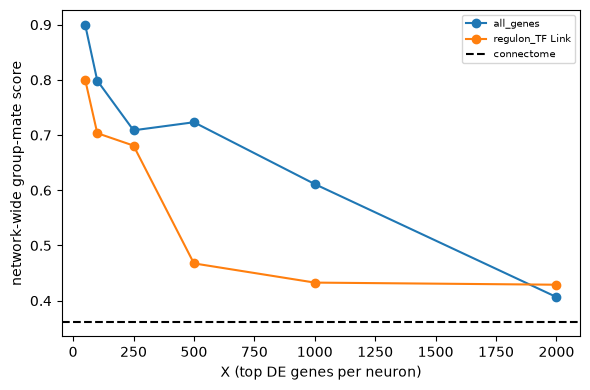

,source,X,score,null_mean,p,ARI,NMI
0,connectome,NaN,0.362,0.275,0.005,0.039,0.153
1,all_genes,50.0,0.900,0.892,0.005,-0.001,0.087
2,all_genes,100.0,0.799,0.719,0.005,0.092,0.264
3,all_genes,250.0,0.709,0.610,0.005,0.112,0.321
4,all_genes,500.0,0.723,0.477,0.005,0.307,0.535
5,all_genes,1000.0,0.611,0.392,0.005,0.294,0.408
6,all_genes,2000.0,0.407,0.309,0.005,0.108,0.211
7,regulon_TF Link,50.0,0.800,0.696,0.005,0.082,0.264
8,regulon_TF Link,100.0,0.703,0.579,0.005,0.141,0.351
9,regulon_TF Link,250.0,0.681,0.420,0.005,0.314,0.500


In [8]:
# Run Analysis 3
a3 = analysis3(conn, nets, types, K_COMMUNITIES, N_PERM, OUT, SEED)
a3.round(3)

In [1]:
"""
Analysis 3 (redesigned): community structure and adjacency agreement of the predicted (expression) networks.

Needs from the notebook / grn_connectome_analysis.py: nets = {(source, X): (graph, weight matrix)}, the connectome
graph `conn`, `nodes` (list), `types` (Series node -> neuron type).

Part 1A   predicted networks -> K=4 communities by spectral clustering of the (density-matched) adjacency matrix.
          Each community is matched to a canonical neuron type (Hungarian assignment). Figure: for each community,
          the % of its nodes carrying each type annotation vs X.
Part 1B   number of communities in the connectome (Louvain modularity maximisation, compared with a degree-preserving
          null). Predicted networks are clustered into that many communities, matched to the connectome's communities,
          and the same figure is drawn with the connectome communities as the annotation: is the connectome's structure
          sustained as X increases?
Part 2    adjacency matrices of the connectome and each predicted network; normalised absolute difference
          sum|A_conn - A_pred| / (E_conn + E_pred) for the whole network and separately within each neuron type and
          between types, versus X, against permutation nulls.
"""
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import SpectralClustering
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

TYPE_ORDER = ["sensory", "interneuron", "motor", "pharyngeal"]
TYPE_COLORS = {"sensory": "#1b9e77", "interneuron": "#7570b3", "motor": "#d95f02", "pharyngeal": "#e7298a"}
COMM_COLORS = ["#4e79a7", "#f28e2b", "#59a14f", "#e15759", "#b07aa1", "#76b7b2", "#edc948", "#9c755f"]


def _bh_fdr(p):
    p = np.asarray(p, float)
    ok = np.isfinite(p)
    q = np.full(p.shape, np.nan)
    if ok.sum():
        v = p[ok]
        o = np.argsort(v)
        r = np.minimum.accumulate((v[o] * len(v) / (np.arange(len(v)) + 1))[::-1])[::-1]
        out = np.empty_like(v)
        out[o] = np.minimum(r, 1.0)
        q[ok] = out
    return q


def _slug(s):
    return "".join(c if c.isalnum() else "_" for c in str(s)).strip("_")


def _sources_in(nets):
    return sorted({s for s, _ in nets})


def _nets_for(nets, source):
    return sorted(((X, v) for (s, X), v in nets.items() if s == source), key=lambda t: t[0])


def _label(ax, text):
    ax.text(0.0, 1.0, text, transform=ax.transAxes, fontsize=14, fontweight="bold", va="bottom", ha="right")


# ----------------------------------------------------------------------------
# Clustering helpers
# ----------------------------------------------------------------------------
def _cluster(G, nodes, k, affinity="binary", seed=0):
    """Spectral clustering of a graph into k communities. affinity: 'binary' (edge present/absent) or 'weighted'."""
    A = nx.to_numpy_array(G, nodelist=nodes, weight=None if affinity == "binary" else "weight") + 1e-6
    np.fill_diagonal(A, 0.0)
    return SpectralClustering(n_clusters=k, affinity="precomputed", random_state=seed,
                              assign_labels="kmeans", n_init=20).fit_predict(A)


def _match_rows(comm, ann_vals, classes):
    """Hungarian-match communities to annotation classes. Returns {class: row} for each matched class."""
    ids = np.unique(comm)
    ct = np.array([[np.sum((comm == c) & (ann_vals == a)) for a in classes] for c in ids])
    r, c = linear_sum_assignment(-ct)
    rows = {}
    for ri, ci in zip(r, c):
        size = ct[ri].sum()
        row = {"community": int(ids[ri]), "size": int(size)}
        for j, b in enumerate(classes):
            row[f"pct_{b}"] = 100.0 * ct[ri, j] / size if size else np.nan
        row["recall"] = 100.0 * ct[ri, ci] / max(ct[:, ci].sum(), 1)       # % of class a's nodes inside this community
        rows[classes[ci]] = row
    return rows


# ----------------------------------------------------------------------------
# Part 1B step 1: how many communities does the connectome have?
# ----------------------------------------------------------------------------
def determine_null_communities(conn, nodes, n_seeds=100, n_null=30, seed=0):
    """Louvain modularity maximisation on the binary connectome, `n_seeds` restarts; the best-modularity partition is
    kept. Compared with the same procedure on degree-preserving edge-swapped graphs (best of 5 restarts each)."""
    G = nx.Graph(conn)
    M = G.number_of_edges()
    best_q, best, ks = -1.0, None, []
    for s in range(n_seeds):
        comms = nx.community.louvain_communities(G, weight=None, resolution=1.0, seed=seed + s)
        q = nx.community.modularity(G, comms, weight=None)
        ks.append(len(comms))
        if q > best_q:
            best_q, best = q, comms
    comms = sorted(best, key=lambda c: (-len(c), sorted(c)[0]))
    labels = pd.Series({n: f"C{i + 1}" for i, c in enumerate(comms) for n in c}).reindex(nodes)

    null_q = []
    for i in range(n_null):
        H = G.copy()
        nx.double_edge_swap(H, nswap=5 * M, max_tries=100 * M, seed=seed + 1000 + i)
        null_q.append(max(nx.community.modularity(H, nx.community.louvain_communities(H, weight=None, seed=seed + j),
                                                  weight=None) for j in range(5)))
    null_q = np.array(null_q)

    res_rows = []
    for r in (0.5, 0.75, 1.0, 1.25, 1.5, 2.0):
        kk = [len(nx.community.louvain_communities(G, weight=None, resolution=r, seed=seed + s)) for s in range(20)]
        res_rows.append(dict(resolution=r, k_most_common=Counter(kk).most_common(1)[0][0], k_min=min(kk), k_max=max(kk)))
    return dict(labels=labels, k=len(comms), sizes=[len(c) for c in comms], modularity=best_q,
                k_counts=dict(sorted(Counter(ks).items())), null_q_mean=null_q.mean(), null_q_sd=null_q.std(ddof=1),
                z=(best_q - null_q.mean()) / null_q.std(ddof=1),
                p=(1 + np.sum(null_q >= best_q)) / (1 + len(null_q)), resolution_table=pd.DataFrame(res_rows))


def describe_null_communities(info, types, out=None):
    ct = pd.crosstab(info["labels"], types.reindex(info["labels"].index)).reindex(columns=TYPE_ORDER, fill_value=0)
    print(f"Connectome communities (Louvain, resolution 1): K = {info['k']}, sizes = {info['sizes']}")
    print(f"  modularity Q = {info['modularity']:.3f}; degree-preserving null Q = {info['null_q_mean']:.3f} "
          f"+/- {info['null_q_sd']:.3f}  (z = {info['z']:.1f}, empirical p = {info['p']:.3g})")
    print(f"  K across Louvain restarts: {info['k_counts']}")
    print("  K vs resolution:\n" + info["resolution_table"].to_string(index=False))
    print("  community x canonical type (node counts):\n" + ct.to_string())
    if out is not None:
        ct.to_csv(Path(out) / "analysis3_connectome_communities_by_type.csv")
        info["labels"].rename("community").to_csv(Path(out) / "analysis3_connectome_communities.csv")
        info["resolution_table"].to_csv(Path(out) / "analysis3_connectome_K_vs_resolution.csv", index=False)
    return ct


# ----------------------------------------------------------------------------
# Part 1: community composition versus X
# ----------------------------------------------------------------------------
def community_composition_vs_x(nets, nodes, ann, k, source, classes, affinity="binary", seed=0):
    ann_vals = ann.reindex(nodes).values
    out = []
    for X, (G, _) in _nets_for(nets, source):
        rows = _match_rows(_cluster(G, nodes, k, affinity, seed), ann_vals, classes)
        out += [dict(source=source, X=X, annotation=a, **rows[a]) for a in classes if a in rows]
    return pd.DataFrame(out)


def reference_composition(conn, nodes, ann, k, classes, affinity="binary", seed=0):
    rows = _match_rows(_cluster(conn, nodes, k, affinity, seed), ann.reindex(nodes).values, classes)
    return pd.DataFrame([dict(annotation=a, **rows[a]) for a in classes if a in rows])


def plot_composition(df, classes, colors, names, ref, base, title, path, fig_no=""):
    n = len(classes)
    ncols = 2 if n <= 4 else 3
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.4 * ncols, 3.8 * nrows + 0.9), sharey=True, squeeze=False)
    axes = axes.flatten()
    for ax in axes[n:]:
        ax.axis("off")
    for i, (ax, a) in enumerate(zip(axes, classes)):
        d = df[df.annotation == a].sort_values("X")
        for b in classes:
            ax.plot(d.X, d[f"pct_{b}"], marker="o", ms=4, color=colors[b], lw=2.8 if b == a else 1.2,
                    alpha=1.0 if b == a else 0.85, zorder=3 if b == a else 2)
        if ref is not None and a in set(ref.annotation):
            ax.axhline(ref.loc[ref.annotation == a, f"pct_{a}"].iloc[0], color="k", ls="--", lw=1, zorder=1)
        ax.axhline(base[a], color="0.55", ls=":", lw=1.2, zorder=1)
        ax.set_xscale("log")
        ax.set_ylim(-2, 102)
        ax.set_title(f"Community matched to {names[a]}", fontsize=10)
        ax.set_xlabel("X (top DE genes per neuron)", fontsize=8)
        _label(ax, f"{fig_no}{'ABCDEFGH'[i]}")
    handles = [plt.Line2D([0], [0], color=colors[b], marker="o", ms=4, lw=2, label=f"% {names[b]}") for b in classes]
    if ref is not None:
        handles.append(plt.Line2D([0], [0], color="k", ls="--", lw=1, label="connectome's own clustering (same method)"))
    handles.append(plt.Line2D([0], [0], color="0.55", ls=":", lw=1.2, label="chance (base rate of matched class)"))
    fig.supylabel("% of the community's nodes with each annotation", fontsize=9)
    fig.suptitle(title, fontsize=11)
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.0), ncol=3 if len(handles) > 5 else 4,
               frameon=False, fontsize=8)
    fig.tight_layout(rect=(0.02, 0.1 if len(handles) > 5 else 0.07, 1, 0.95))
    fig.savefig(path, dpi=200)
    plt.show()


def analysis3_part1a(conn, nets, nodes, types, source, out, k=4, affinity="binary", seed=0, fig_no=""):
    """Predicted networks -> k communities, matched to canonical neuron types."""
    out = Path(out)
    ann = types.reindex(nodes)
    classes = [t for t in TYPE_ORDER if t in set(ann)]
    df = community_composition_vs_x(nets, nodes, ann, k, source, classes, affinity, seed)
    ref = reference_composition(conn, nodes, ann, k, classes, affinity, seed)
    df.to_csv(out / f"analysis3_part1A_{_slug(source)}.csv", index=False)
    ref.to_csv(out / "analysis3_part1A_connectome_reference.csv", index=False)
    base = {a: 100.0 * (ann == a).mean() for a in classes}
    plot_composition(df, classes, TYPE_COLORS, {a: a for a in classes}, ref, base,
                     f"Part 1A: {source} networks split into {k} communities, annotated by canonical neuron type",
                     out / f"analysis3_part1A_{_slug(source)}.png", fig_no)
    return df, ref


def analysis3_part1b(conn, nets, nodes, types, source, null_info, out, affinity="binary", seed=0, fig_no=""):
    """Predicted networks -> K communities (K = connectome's), matched to the connectome's own communities."""
    out = Path(out)
    ann = null_info["labels"]
    k = null_info["k"]
    classes = list(pd.Series(ann).value_counts().sort_index().index)            # C1..CK (largest first)
    ct = pd.crosstab(ann, types.reindex(ann.index)).reindex(columns=TYPE_ORDER, fill_value=0)
    names = {c: f"{c} ({ct.loc[c].idxmax()}, n={int(ct.loc[c].sum())})" for c in classes}
    colors = {c: COMM_COLORS[i % len(COMM_COLORS)] for i, c in enumerate(classes)}
    df = community_composition_vs_x(nets, nodes, ann, k, source, classes, affinity, seed)
    ref = reference_composition(conn, nodes, ann, k, classes, affinity, seed)
    df.to_csv(out / f"analysis3_part1B_{_slug(source)}.csv", index=False)
    ref.to_csv(out / "analysis3_part1B_connectome_reference.csv", index=False)
    base = {c: 100.0 * (ann == c).mean() for c in classes}
    plot_composition(df, classes, colors, names, ref, base,
                     f"Part 1B: {source} networks split into {k} communities, annotated by the connectome's communities",
                     out / f"analysis3_part1B_{_slug(source)}.png", fig_no)
    return df, ref


# ----------------------------------------------------------------------------
# Part 1 summary: ARI / NMI versus X
# ----------------------------------------------------------------------------
def analysis3_agreement(conn, nets, nodes, types, null_info, source, out, k_types=4, affinity="binary", seed=0):
    out = Path(out)
    schemes = {"canonical types": (types.reindex(nodes), k_types),
               "connectome communities": (null_info["labels"], null_info["k"])}
    rows, ref_rows = [], []
    for name, (ann, k) in schemes.items():
        av = ann.reindex(nodes).values
        rc = _cluster(conn, nodes, k, affinity, seed)
        ref_rows.append(dict(scheme=name, ARI=adjusted_rand_score(av, rc), NMI=normalized_mutual_info_score(av, rc)))
        for X, (G, _) in _nets_for(nets, source):
            c = _cluster(G, nodes, k, affinity, seed)
            rows.append(dict(source=source, scheme=name, X=X, ARI=adjusted_rand_score(av, c),
                             NMI=normalized_mutual_info_score(av, c)))
    df, ref = pd.DataFrame(rows), pd.DataFrame(ref_rows)
    df.to_csv(out / f"analysis3_agreement_{_slug(source)}.csv", index=False)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
    cols = {"canonical types": "#333333", "connectome communities": "#c44e52"}
    for ax, m in zip(axes, ["ARI", "NMI"]):
        for name in schemes:
            d = df[df.scheme == name].sort_values("X")
            ax.plot(d.X, d[m], marker="o", color=cols[name], label=name)
            ax.axhline(ref.loc[ref.scheme == name, m].iloc[0], color=cols[name], ls="--", lw=1)
        ax.set_xscale("log")
        ax.set_xlabel("X (top DE genes per neuron)")
        ax.set_ylabel(m)
        ax.set_title(f"{m} between predicted-network communities and annotation")
    axes[0].legend(fontsize=8, title="annotation (dashed = connectome's own clustering)", title_fontsize=7)
    fig.tight_layout()
    fig.savefig(out / f"analysis3_agreement_{_slug(source)}.png", dpi=200)
    plt.show()
    return df, ref


# ----------------------------------------------------------------------------
# Part 2: adjacency matrices and absolute difference
# ----------------------------------------------------------------------------
def _scope_masks(tv):
    n = len(tv)
    iu = np.triu(np.ones((n, n), bool), 1)
    masks = {"overall": iu}
    for t in TYPE_ORDER:
        if t in set(tv):
            masks[f"within {t}"] = iu & (tv[:, None] == t) & (tv[None, :] == t)
    masks["between types"] = iu & (tv[:, None] != tv[None, :])
    return masks


def _norm_diff(a, b):
    ec, ep = a.sum(), b.sum()
    return (ec + ep - 2 * (a * b).sum()) / (ec + ep) if ec + ep > 0 else np.nan


def adjacency_difference_vs_x(conn, nets, nodes, types, source, n_perm=500, seed=0):
    """Normalised absolute difference  sum|A_conn - A_pred| / (E_conn + E_pred)  per scope and X.
    0 = identical edge sets, 1 = no shared edges. Nulls relabel the predicted network's nodes (A_pred[p][:, p]):
      'random'          any permutation (breaks type structure too),
      'type-preserving' permutes only within neuron type (keeps type-level structure, breaks neuron-level match)."""
    rng = np.random.default_rng(seed)
    tv = types.reindex(nodes).values
    n = len(nodes)
    masks = _scope_masks(tv)
    idx = {k: np.flatnonzero(m.ravel()) for k, m in masks.items()}
    Ac = nx.to_numpy_array(conn, nodelist=nodes, weight=None)
    ac = {k: Ac.ravel()[i] for k, i in idx.items()}
    groups = [np.where(tv == t)[0] for t in np.unique(tv)]
    rows = []
    for X, (G, _) in _nets_for(nets, source):
        Ap = nx.to_numpy_array(G, nodelist=nodes, weight=None)
        null = {"random": {k: [] for k in idx}, "type": {k: [] for k in idx}}
        for _ in range(n_perm):
            p_r = rng.permutation(n)
            p_t = np.arange(n)
            for g in groups:
                p_t[g] = rng.permutation(g)
            for tag, p in (("random", p_r), ("type", p_t)):
                flat = Ap[np.ix_(p, p)].ravel()
                for k, i in idx.items():
                    null[tag][k].append(_norm_diff(ac[k], flat[i]))
        flat = Ap.ravel()
        for k, i in idx.items():
            a, b = ac[k], flat[i]
            obs = _norm_diff(a, b)
            row = dict(source=source, X=X, scope=k, n_pairs=len(i), edges_connectome=int(a.sum()),
                       edges_predicted=int(b.sum()), shared_edges=int((a * b).sum()),
                       abs_diff=int(a.sum() + b.sum() - 2 * (a * b).sum()), norm_diff=obs)
            for tag in ("random", "type"):
                nl = np.array(null[tag][k])
                row.update({f"null_{tag}_median": np.nanmedian(nl), f"null_{tag}_lo": np.nanpercentile(nl, 2.5),
                            f"null_{tag}_hi": np.nanpercentile(nl, 97.5),
                            f"p_{tag}": (1 + np.sum(nl <= obs)) / (1 + len(nl))})   # one-sided: closer than chance
            rows.append(row)
    df = pd.DataFrame(rows)
    df["fdr_type"] = _bh_fdr(df["p_type"].values)
    return df


def plot_adjacency_difference(df, source, path, fig_no=""):
    scopes = list(dict.fromkeys(df.scope))
    ncols = 3
    nrows = int(np.ceil(len(scopes) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 3.7 * nrows + 0.9), sharey=True, squeeze=False)
    axes = axes.flatten()
    for ax in axes[len(scopes):]:
        ax.axis("off")
    for i, (ax, sc) in enumerate(zip(axes, scopes)):
        d = df[df.scope == sc].sort_values("X")
        col = "k" if sc == "overall" else TYPE_COLORS.get(sc.replace("within ", ""), "#555555")
        if sc == "overall":
            ax.fill_between(d.X, d.null_random_lo, d.null_random_hi, color="#dddddd")
            ax.plot(d.X, d.null_random_median, color="0.6", lw=1)
        ax.fill_between(d.X, d.null_type_lo, d.null_type_hi, color="#bbbbbb", alpha=0.8 if sc != "overall" else 0.6)
        ax.plot(d.X, d.null_type_median, color="0.4", lw=1)
        ax.plot(d.X, d.norm_diff, marker="o", color=col, lw=2.4, zorder=3)
        for _, r in d.iterrows():
            if r.fdr_type < 0.05:
                ax.text(r.X, r.norm_diff - 0.035, "*", ha="center", va="top", fontsize=13)
        ax.set_xscale("log")
        ax.set_title(f"{sc}\n(connectome edges: {int(d.edges_connectome.iloc[0])}, pairs: {int(d.n_pairs.iloc[0])})",
                     fontsize=9)
        ax.set_xlabel("X (top DE genes per neuron)", fontsize=8)
        _label(ax, f"{fig_no}{'ABCDEFGH'[i]}")
    h = [plt.Line2D([0], [0], color="k", marker="o", lw=2, label="predicted vs connectome"),
         plt.Rectangle((0, 0), 1, 1, color="#bbbbbb", label="null: relabel within neuron type (95% interval)"),
         plt.Rectangle((0, 0), 1, 1, color="#dddddd", label="null: random relabel, overall panel (95% interval)")]
    fig.supylabel("normalised absolute difference  sum|A_conn - A_pred| / (E_conn + E_pred)\n"
                  "(0 = identical, 1 = no shared edges; lower = closer)", fontsize=8)
    fig.suptitle(f"Part 2: {source} adjacency difference vs top-X genes", fontsize=11)
    fig.legend(handles=h, loc="lower center", bbox_to_anchor=(0.5, 0.0), ncol=3, frameon=False, fontsize=8)
    fig.text(0.99, 0.045, "* FDR < 0.05 vs the within-type relabel null", ha="right", fontsize=7)
    fig.tight_layout(rect=(0.03, 0.09, 1, 0.95))
    fig.savefig(path, dpi=200)
    plt.show()


def plot_adjacency_comparison(conn, nets, nodes, types, source, X, path, fig_no=""):
    """Connectome adjacency, predicted adjacency and |difference|, neurons ordered by canonical type."""
    order = sorted(nodes, key=lambda n: (TYPE_ORDER.index(types[n]) if types[n] in TYPE_ORDER else 9, n))
    G = dict(_nets_for(nets, source))[X][0]
    Ac = nx.to_numpy_array(conn, nodelist=order, weight=None)
    Ap = nx.to_numpy_array(G, nodelist=order, weight=None)
    D = np.abs(Ac - Ap)
    bounds = np.cumsum([sum(types[n] == t for n in order) for t in TYPE_ORDER])[:-1]
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.3))
    for ax, M, title, lab in zip(axes, [Ac, Ap, D],
                                 [f"Connectome ({int(Ac.sum() / 2)} edges)", f"{source}, X = {X} ({int(Ap.sum() / 2)} edges)",
                                  f"|difference| ({int(D.sum() / 2)} mismatched pairs)"], "ABC"):
        ax.imshow(M, cmap="Greys", interpolation="nearest")
        for b in bounds:
            ax.axhline(b - 0.5, color="#c44e52", lw=0.8)
            ax.axvline(b - 0.5, color="#c44e52", lw=0.8)
        ax.set_title(title, fontsize=10)
        ax.set_xticks([])
        ax.set_yticks([])
        _label(ax, f"{fig_no}{lab}")
    mids = (np.r_[0, bounds] + np.r_[bounds, len(order)]) / 2
    for ax in axes:
        ax.set_xticks(mids)
        ax.set_xticklabels(TYPE_ORDER, fontsize=8)
        ax.set_yticks(mids)
        ax.set_yticklabels(TYPE_ORDER, fontsize=8, rotation=90, va="center")
    fig.tight_layout()
    fig.savefig(path, dpi=200)
    plt.show()


def analysis3_part2(conn, nets, nodes, types, source, out, n_perm=500, seed=0, fig_no="", show_X=None):
    out = Path(out)
    df = adjacency_difference_vs_x(conn, nets, nodes, types, source, n_perm, seed)
    df.to_csv(out / f"analysis3_part2_{_slug(source)}.csv", index=False)
    plot_adjacency_difference(df, source, out / f"analysis3_part2_{_slug(source)}.png", fig_no)
    Xs = sorted(df.X.unique())
    plot_adjacency_comparison(conn, nets, nodes, types, source, show_X if show_X in Xs else Xs[len(Xs) // 2],
                              out / f"analysis3_part2_adjacency_{_slug(source)}.png", fig_no)
    print(df[df.scope == "overall"][["X", "edges_predicted", "shared_edges", "abs_diff", "norm_diff",
                                     "null_random_median", "null_type_median", "p_random", "p_type"]].round(3).to_string(index=False))
    return df

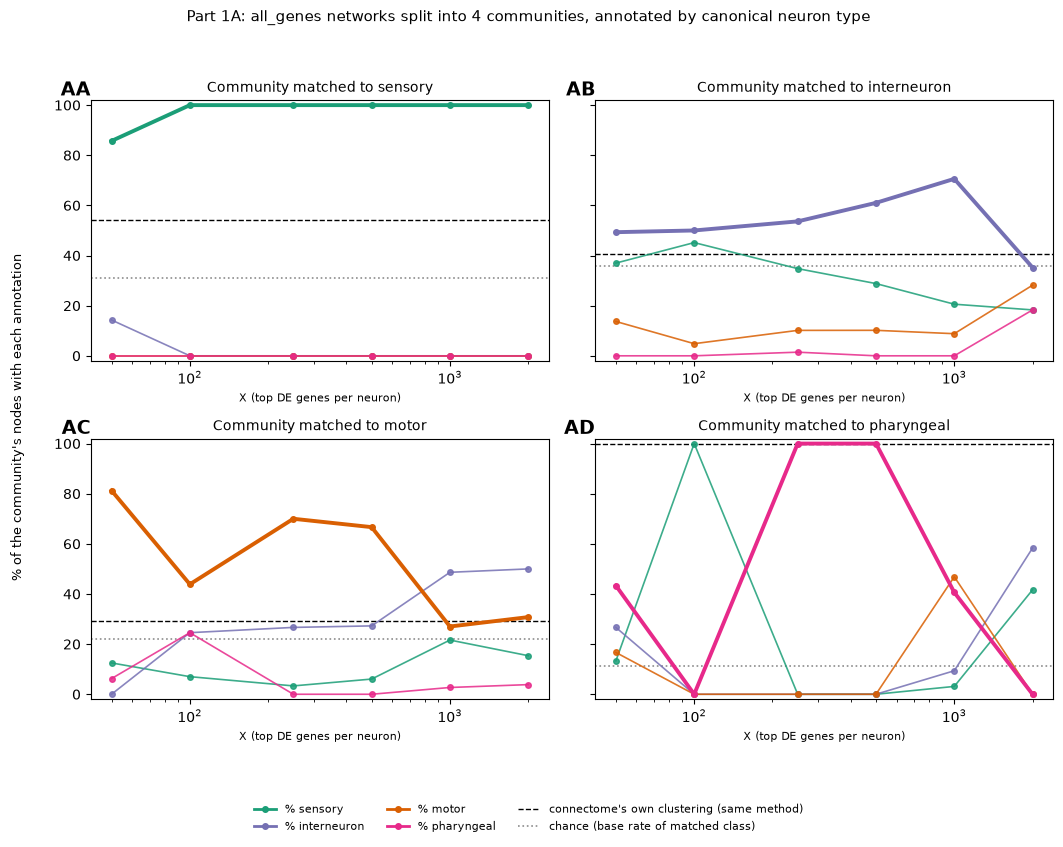

AttributeError: 'DataFrame' object has no attribute 'annotation'

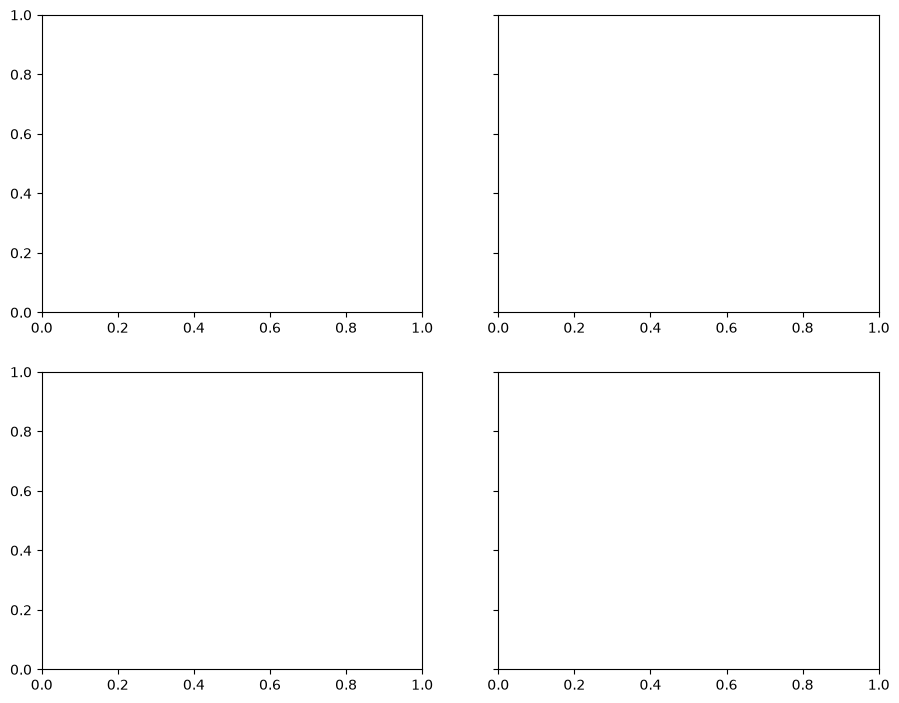

In [9]:


null_info = determine_null_communities(conn, nodes, n_seeds=100, n_null=30, seed=SEED)
analysis3_part1a(conn, nets, nodes, types, "all_genes", OUT, k=K_COMMUNITIES, affinity="binary", seed=SEED, fig_no="A")
analysis3_part1a(conn, nets, nodes, types, "TF Link", OUT, k=K_COMMUNITIES, affinity="binary", seed=SEED, fig_no="B")
analysis3_part1b(conn, nets, nodes, types, "all_genes", null_info, OUT, affinity="binary", seed=SEED, fig_no="C")
analysis3_part1b(conn, nets, nodes, types, "TF Link", null_info, OUT, affinity="binary", seed=SEED, fig_no="D")
analysis3_agreement(conn, nets, nodes, types, null_info, "all_genes", OUT, k_types=K_COMMUNITIES, affinity="binary", seed=SEED)
analysis3_agreement(conn, nets, nodes, types, null_info, "TF Link", OUT, k_types=K_COMMUNITIES, affinity="binary", seed=SEED)  
analysis3_part2(conn, nets, nodes, types, "all_genes", OUT, N_PERM, SEED, fig_no="G", show_X=100)
analysis3_part2(conn, nets, nodes, types, "TF Link", OUT, N_PERM, SEED, fig_no="H", show_X=100)